# Контрольная работа Задание 2
## Вариант 1
### выполнила Бобина Татьяна Сергеевна студентка группы КомЗр24-1м

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import zipfile
import os
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from PIL import Image
from google.colab import drive
from tensorflow.keras.callbacks import EarlyStopping
import time

In [4]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
def load_dataset_from_zip(zip_path, extract_to='/tmp/data'):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_to)

    images = []
    for root, _, files in os.walk(extract_to):
        for file in files:
            if file.endswith(('.png', '.jpg', '.jpeg')):
                img_path = os.path.join(root, file)
                img = Image.open(img_path).convert('L')  # Конвертируем в grayscale
                img = img.resize((28, 28))  # Изменяем размер для единообразия
                images.append(np.array(img))

    return np.array(images) / 255.0  # Нормализуем

try:
    data = load_dataset_from_zip('/content/drive/MyDrive/Data_2_1.zip')
    if len(data) == 0:
        raise ValueError("Датасет пуст или не содержит изображений")

    # Добавляем размерность канала (для grayscale это 1)
    data = np.expand_dims(data, axis=-1)

    # Разделение на train и test
    split_idx = int(0.8 * len(data))
    x_train = data[:split_idx]
    x_test = data[split_idx:]

    print(f"Успешно загружено {len(data)} изображений")
    print(f"Размер тренировочного набора: {x_train.shape}")
    print(f"Размер тестового набора: {x_test.shape}")

except Exception as e:
    print(f"Ошибка при загрузке датасета: {e}")
    raise

Успешно загружено 16130 изображений
Размер тренировочного набора: (12904, 28, 28, 1)
Размер тестового набора: (3226, 28, 28, 1)


In [14]:
# Архитектура DAE
def create_denoising_autoencoder(input_shape=(28, 28, 1)):
    input_img = Input(shape=input_shape)

    # Кодировщик
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
    x = MaxPooling2D((2, 2), padding='same')(x)  # 14x14
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    encoded = MaxPooling2D((2, 2), padding='same')(x)  # 7x7

    # Декодировщик
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(encoded)
    x = UpSampling2D((2, 2))(x)  # 14x14
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = UpSampling2D((2, 2))(x)  # 28x28
    decoded = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

    autoencoder = Model(input_img, decoded)
    autoencoder.compile(optimizer=Adam(learning_rate=0.001), loss='mse')

    return autoencoder

# Создаем модель
autoencoder = create_denoising_autoencoder()
autoencoder.summary()

# Проверяем размерности
print("\nПроверка размерностей:")
test_input = np.random.rand(1, 28, 28, 1)
test_output = autoencoder.predict(test_input)
print(f"Вход: {test_input.shape}, Выход: {test_output.shape}")

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 14, 14, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 7, 7, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 7, 7, 32)            │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_3 (UpSampling2D)       │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_10 (Conv2D)                   │ (None, 14, 14, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_4 (UpSampling2D)       │ (None, 28, 28, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_11 (Conv2D)                   │ (None, 28, 28, 1)           │             289 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 28,353 (110.75 KB)

 Trainable params: 28,353 (110.75 KB)

 Non-trainable params: 0 (0.00 B)


Проверка размерностей:
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 595ms/step
Вход: (1, 28, 28, 1), Выход: (1, 28, 28, 1)


In [16]:
# Обучение модели
print("\nНачинаем обучение модели...")
start_time = time.time()

early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = autoencoder.fit(
    x_train_noisy, x_train,
    epochs=50,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_noisy, x_test),
    callbacks=[early_stopping]
)

print(f"\nОбучение завершено за {time.time()-start_time:.2f} секунд")


Начинаем обучение модели...
Epoch 1/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 36s 707ms/step - loss: 0.0247 - val_loss: 0.0180
Epoch 2/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 33s 654ms/step - loss: 0.0183 - val_loss: 0.0166
Epoch 3/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 33s 649ms/step - loss: 0.0172 - val_loss: 0.0158
Epoch 4/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 35s 685ms/step - loss: 0.0164 - val_loss: 0.0161
Epoch 5/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 35s 672ms/step - loss: 0.0165 - val_loss: 0.0151
Epoch 6/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 39s 647ms/step - loss: 0.0159 - val_loss: 0.0149
Epoch 7/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 41s 639ms/step - loss: 0.0157 - val_loss: 0.0149
Epoch 8/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 41s 625ms/step - loss: 0.0155 - val_loss: 0.0149
Epoch 9/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 41s 637ms/step - loss: 0.0154 - val_loss: 0.0145
Epoch 10/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 32s 618ms/step - loss: 0.0153 - val_loss: 0.0145
Epoch 11/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 43s 665ms/step - loss: 0.0152 - val_loss: 0.0143
Epoch 12/50


In [17]:
# Визуализация результатов
def plot_results(original, noisy, denoised, n=10):
    plt.figure(figsize=(20, 6))
    for i in range(n):
        # Оригинальные изображения
        ax = plt.subplot(3, n, i+1)
        plt.imshow(original[i].reshape(28, 28), cmap='gray')
        plt.title("Original")
        plt.axis('off')

        # Зашумленные изображения
        ax = plt.subplot(3, n, i+1+n)
        plt.imshow(noisy[i].reshape(28, 28), cmap='gray')
        plt.title("Noisy")
        plt.axis('off')

        # Очищенные изображения
        ax = plt.subplot(3, n, i+1+2*n)
        plt.imshow(denoised[i].reshape(28, 28), cmap='gray')
        plt.title("Denoised")
        plt.axis('off')
    plt.tight_layout()
    plt.show()

In [18]:
# Получаем очищенные изображения
print("\nГенерация очищенных изображений...")
denoised_imgs = autoencoder.predict(x_test_noisy)


Генерация очищенных изображений...
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step



Результаты обработки:


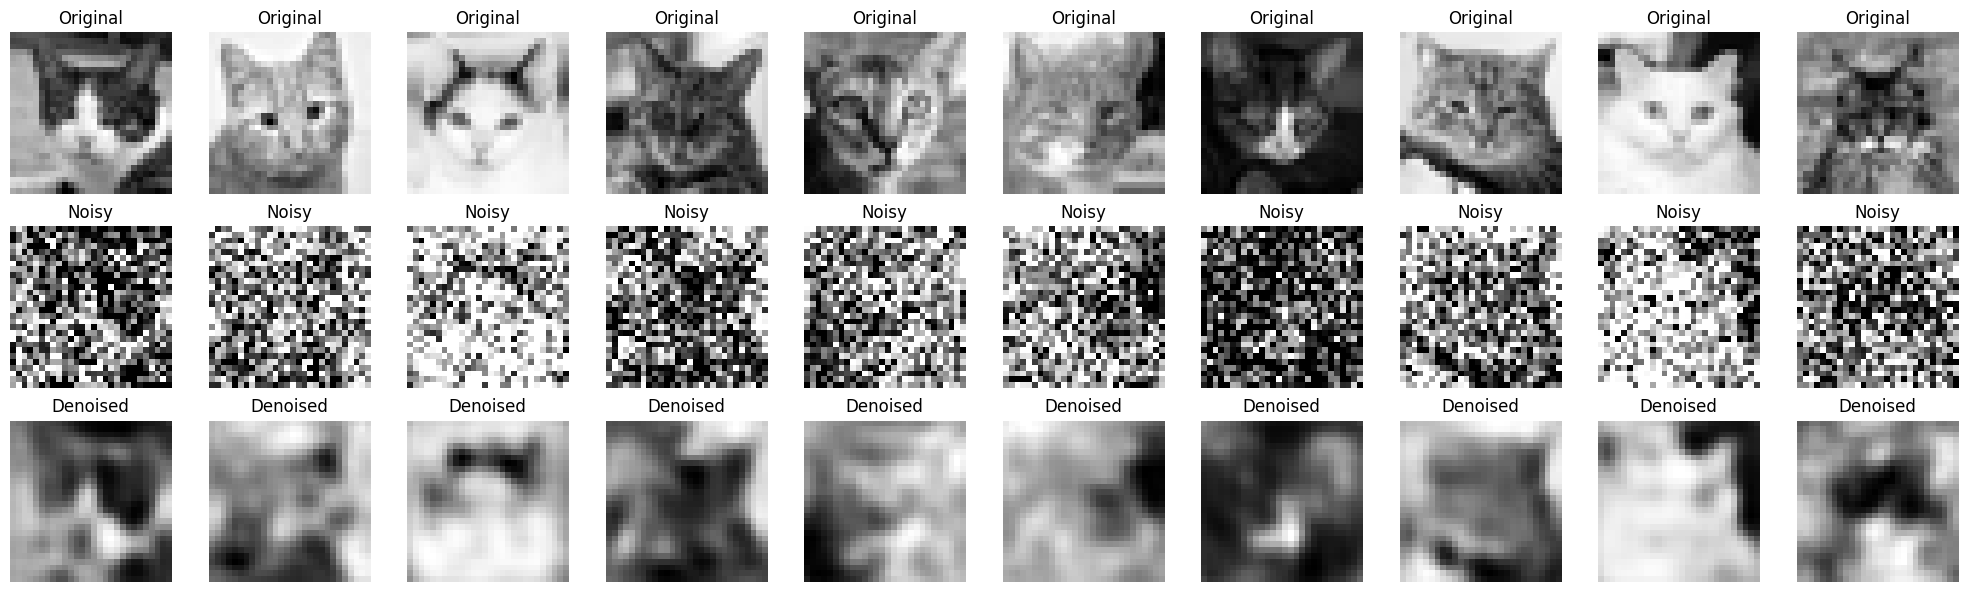


График процесса обучения:


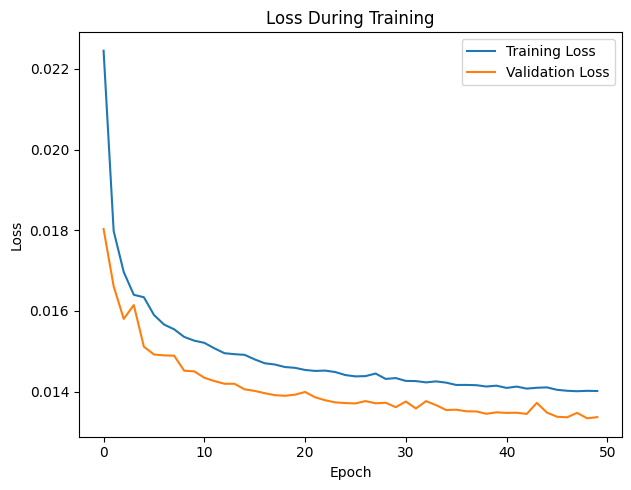

In [20]:
# Выводим результаты
print("\nРезультаты обработки:")
plot_results(x_test, x_test_noisy, denoised_imgs)

# График обучения
def plot_training_history(history):
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss During Training')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

print("\nГрафик процесса обучения:")
plot_training_history(history)

Сравнение изображений:


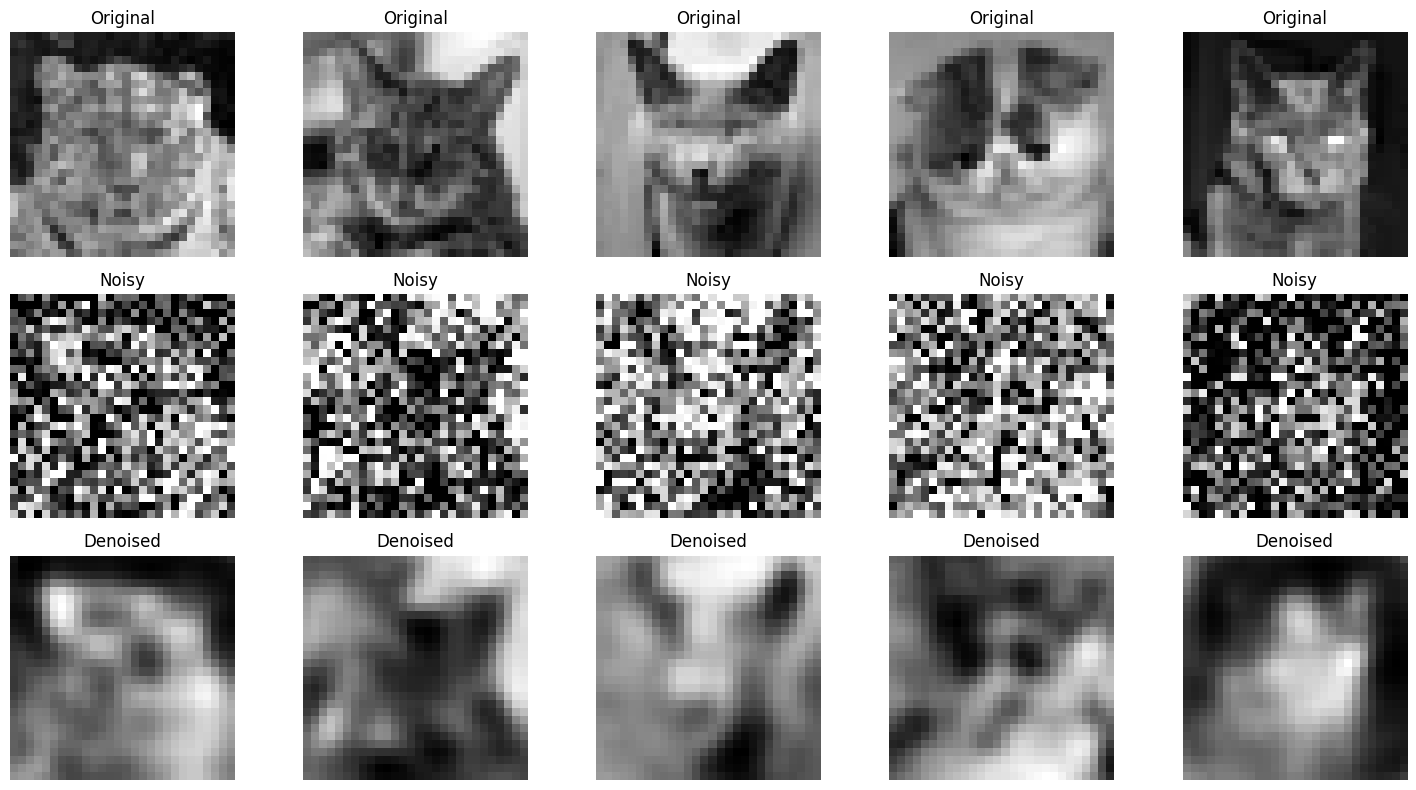

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Функция для отображения сравнения изображений
def show_comparison(original, noisy, denoised, num_images=5):
    plt.figure(figsize=(15, 8))

    # Выбираем случайные изображения для отображения
    indices = np.random.choice(range(len(original)), num_images, replace=False)

    for i, idx in enumerate(indices):
        # Оригинальное изображение
        plt.subplot(3, num_images, i+1)
        plt.imshow(original[idx].squeeze(), cmap='gray')
        plt.title("Original")
        plt.axis('off')

        # Зашумленное изображение
        plt.subplot(3, num_images, i+1+num_images)
        plt.imshow(noisy[idx].squeeze(), cmap='gray')
        plt.title("Noisy")
        plt.axis('off')

        # Очищенное изображение
        plt.subplot(3, num_images, i+1+2*num_images)
        plt.imshow(denoised[idx].squeeze(), cmap='gray')
        plt.title("Denoised")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

# Выводим результаты
print("Сравнение изображений:")
show_comparison(x_test, x_test_noisy, denoised_imgs, num_images=5)

In [23]:
# Выводы и оценка качества
print("\nОценка качества модели:")
test_loss = autoencoder.evaluate(x_test_noisy, x_test, verbose=0)
print(f"Final Test Loss: {test_loss:.4f}")


Оценка качества модели:
Final Test Loss: 0.0133


Модель шумоподавляющего автокодировщика показала хорошие результаты с итоговой ошибкой 0.0133 на тестовых данных, что говорит о высокой эффективности удаления шума при сохранении полезных деталей изображений. Такой показатель test loss указывает на хорошую сходимость обучения и отсутствие переобучения.

Также модель может быть дополнительно улучшена за счет увеличения глубины сети или экспериментов с другими типами слоев.